# Beam widths and M² after ISO 11146

`pyoptics.beam_quality` measures laser beams the way ISO 11146 prescribes:

| Function | Result |
|---|---|
| `second_moments()` | centroid $(\bar x, \bar y)$ and second moments $\sigma_x^2, \sigma_y^2, \sigma_{xy}^2$ of an intensity image |
| `beam_widths()` | widths $d_x, d_y$ along the principal axes and their azimuth $\varphi$, optionally with the iterative integration window of ISO 11146-3 |
| `fit_caustic()` | hyperbolic fit $d^2(z) = a + bz + cz^2$ giving waist $d_0$, waist position $z_0$, divergence $\Theta$, Rayleigh length $z_R$ and $M^2$ |

The widths are second moment diameters,
$d_x = 2\sqrt2\,\bigl(\sigma_x^2 + \sigma_y^2 + \gamma\sqrt{(\sigma_x^2 - \sigma_y^2)^2 + 4\sigma_{xy}^4}\bigr)^{1/2}$
(and $d_y$ with $-\gamma$, $\gamma = \operatorname{sgn}(\sigma_x^2 - \sigma_y^2)$), which
equal $2w$ for a Gaussian beam with $1/e^2$ radius $w$. The beam propagation
ratio is

$$ M^2 = \frac{\pi}{4\lambda}\, d_0\, \Theta, $$

1 for a Gaussian beam and $2l + 1$ for a Hermite-Gaussian $\mathrm{HG}_{lm}$ in $x$.

**Convention:** $\exp(i(\mathbf{k}\cdot\mathbf{r} - \omega t))$; lengths in µm.

In [1]:
import warnings

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse

from pyoptics.beam_quality import beam_widths, fit_caustic
from pyoptics.bases import local_coordinates
from pyoptics.beams import gauss_hermite
from pyoptics.masks import thin_lens
from pyoptics.processing import CameraNoiser, Scaler
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics.utils import grid2d

plt.rcParams.update({"figure.dpi": 100, "image.origin": "lower", "font.size": 11})

## 1. Widths, principal axes and azimuth

Three test beams: a round Gaussian, an elliptical Gaussian rotated by 30°,
and a Hermite-Gaussian $\mathrm{HG}_{10}$ rotated by $-20°$. The ellipses show
$d_x, d_y$ and the principal axes found by `beam_widths()`. The principal
"x" axis is, by ISO's definition, the one closer to the lab $x$ axis
($\lvert\varphi\rvert \le 45°$).

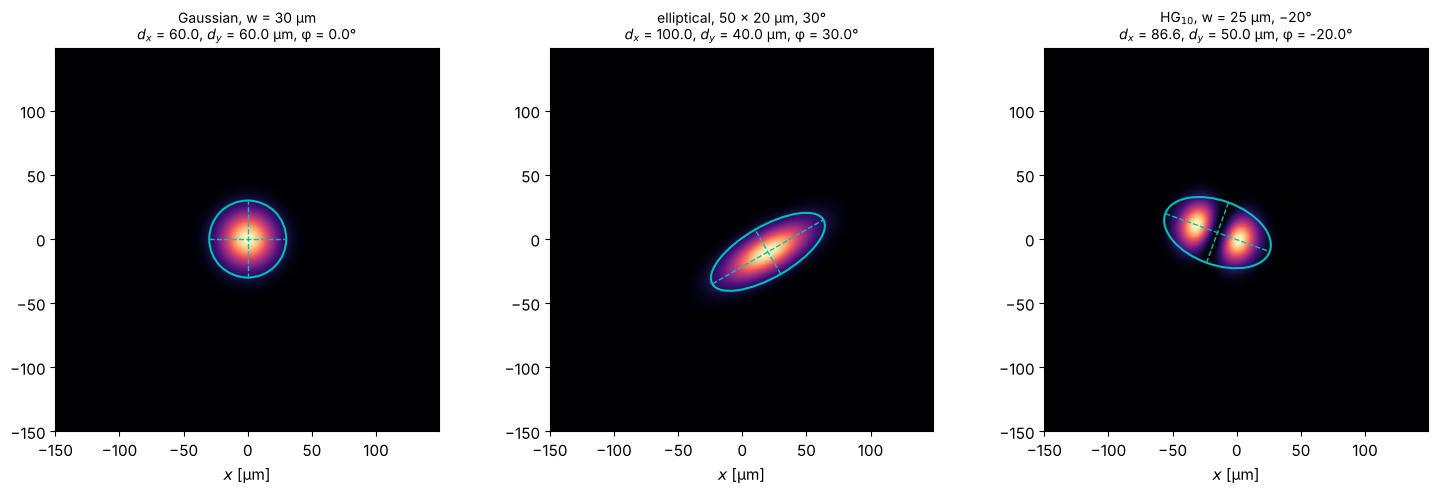

In [2]:
x, y, X, Y = grid2d(-150, 150, -150, 150, 300)
U, V = local_coordinates(X, Y, 20.0, -10.0, np.deg2rad(30))
U2, V2 = local_coordinates(X, Y, -15.0, 5.0, np.deg2rad(-20))
beams = {
    "Gaussian, w = 30 µm": np.exp(-2*(X**2 + Y**2)/30.0**2),
    "elliptical, 50 × 20 µm, 30°": np.exp(-2*(U**2/50.0**2 + V**2/20.0**2)),
    "HG$_{10}$, w = 25 µm, −20°": np.abs(gauss_hermite(1, 0, U2, V2, 0.0, 25.0, 1.0, 1.0))**2,
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8))
for ax, (name, I) in zip(axes, beams.items()):
    b = beam_widths(I, x, y)
    ax.imshow(I, extent=(x[0], x[-1], y[0], y[-1]), cmap="magma")
    ax.add_patch(Ellipse((b.x_c, b.y_c), b.d_x, b.d_y, angle=np.rad2deg(b.phi), fill=False, color="c", lw=1.5))
    for d, ang in ((b.d_x, b.phi), (b.d_y, b.phi + np.pi/2)):
        ax.plot(b.x_c + d/2*np.cos(ang)*np.array([-1, 1]), b.y_c + d/2*np.sin(ang)*np.array([-1, 1]), "c--", lw=1)
    ax.set_title(f"{name}\n$d_x$ = {b.d_x:.1f}, $d_y$ = {b.d_y:.1f} µm, φ = {np.rad2deg(b.phi):.1f}°", fontsize=10)
    ax.set_xlabel("$x$ [µm]")
fig.tight_layout()

The numbers are exact: $2w = 60$ µm for the round beam, $100 \times 40$ µm for
the ellipse, and $2w\sqrt{3} = 86.6$ µm by $2w = 50$ µm for $\mathrm{HG}_{10}$,
whose second moment width in $x$ includes both lobes.

## 2. M² of a focused beam with spherical aberration

A collimated Gaussian beam ($w = 100$ µm, λ = 1 µm) is focused by a lens with
$f = 10$ mm. Spherical aberration is modelled as an additional pupil phase
$2\pi a\,(r/w)^4$ with $a$ in waves at $r = w$. The field is propagated with the
angular spectrum method (`rayleigh_sommerfeld_I_TF`) and measured like in the
lab, in two steps as ISO recommends:

1. a coarse scan over a wide range to locate the waist and estimate $z_R$,
2. the actual measurement: 5 positions within $\pm z_R$ of the waist and 6
   beyond $2 z_R$.

Even the unaberrated beam shows a known Gaussian beam effect: its waist does
not lie in the focal plane but at $f/(1 + (f/z_{R,\mathrm{in}})^2) = 9.08$ mm, closer
to the lens, because the input Rayleigh length $z_{R,\mathrm{in}} = \pi w^2/\lambda = 31$ mm
is not much longer than $f$.

In [3]:
wl, w, f = 1.0, 100.0, 10000.0
x, y, X, Y = grid2d(-600, 600, -600, 600, 512)
R = np.hypot(X, Y)

def widths_along(E, z_positions):
    return [beam_widths(np.abs(rayleigh_sommerfeld_I_TF(E, x, y, z, wl)[0])**2, x, y) for z in z_positions]

def measure(E):
    z_coarse = np.linspace(4000, 16000, 13)
    coarse = fit_caustic(z_coarse, [b.d_x for b in widths_along(E, z_coarse)], wl)
    z_iso = coarse.z_0 + coarse.z_R*np.array([-3, -2.5, -2, -0.8, -0.4, 0, 0.4, 0.8, 2, 2.5, 3])
    d_iso = np.array([b.d_x for b in widths_along(E, z_iso)])
    return z_iso, d_iso, fit_caustic(z_iso, d_iso, wl)

aberrations = (0.0, 0.05, 0.1, 0.15)
results = {}
for a in aberrations:
    E_lens = np.exp(-R**2/w**2)*thin_lens(x, y, f, wl)*np.exp(2j*np.pi*a*(R/w)**4)
    results[a] = (E_lens,) + measure(E_lens)
    fit = results[a][3]
    print(f"a = {a:4.2f} waves:  M² = {fit.M2:.3f}, waist at {fit.z_0/1000:.2f} mm, "
          f"d_0 = {fit.d_0:.1f} µm, z_R = {fit.z_R/1000:.2f} mm, Θ = {1000*fit.theta:.2f} mrad")

a = 0.00 waves:  M² = 1.000, waist at 9.08 mm, d_0 = 60.7 µm, z_R = 2.89 mm, Θ = 20.99 mrad


a = 0.05 waves:  M² = 1.084, waist at 10.51 mm, d_0 = 79.0 µm, z_R = 4.52 mm, Θ = 17.48 mrad


a = 0.10 waves:  M² = 1.255, waist at 11.21 mm, d_0 = 107.9 µm, z_R = 7.29 mm, Θ = 14.80 mrad


a = 0.15 waves:  M² = 1.442, waist at 10.09 mm, d_0 = 139.8 µm, z_R = 10.65 mm, Θ = 13.13 mrad


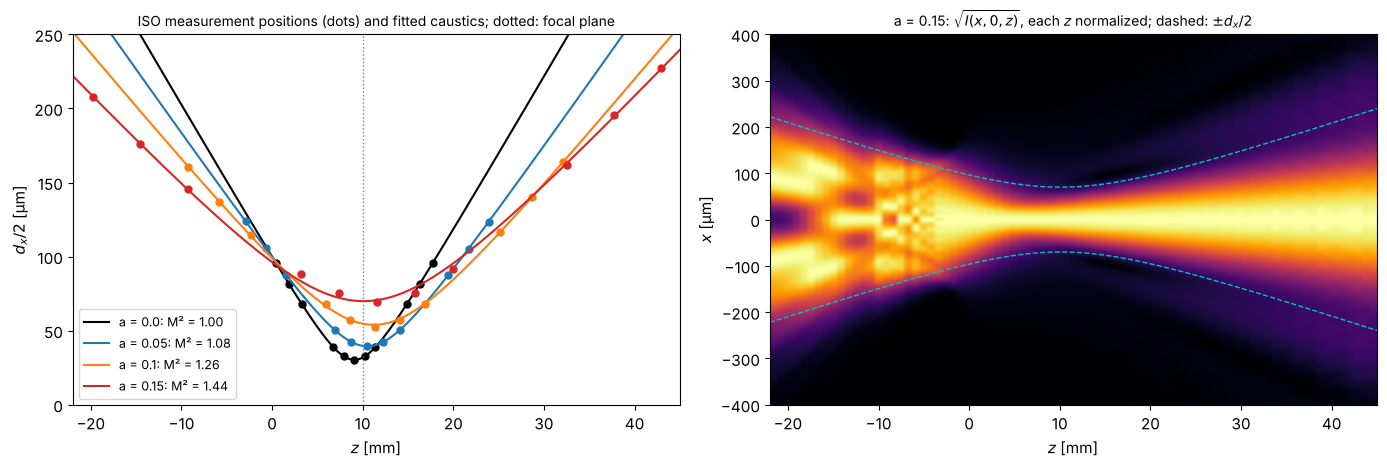

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
z_plot = np.linspace(-22000, 45000, 400)
for (a, (E, z_iso, d_iso, fit)), color in zip(results.items(), ("k", "C0", "C1", "C3")):
    axes[0].plot(z_iso/1000, d_iso/2, "o", color=color, ms=5)
    axes[0].plot(z_plot/1000, fit.d(z_plot)/2, "-", color=color, lw=1.5, label=f"a = {a}: M² = {fit.M2:.2f}")
axes[0].axvline(f/1000, color="gray", ls=":", lw=1)
axes[0].set_xlim(z_plot[0]/1000, z_plot[-1]/1000); axes[0].set_ylim(0, 250)
axes[0].set_xlabel("$z$ [mm]"); axes[0].set_ylabel("$d_x/2$ [µm]")
axes[0].set_title("ISO measurement positions (dots) and fitted caustics; dotted: focal plane", fontsize=10)
axes[0].legend(fontsize=9)

E, z_iso, d_iso, fit = results[0.15]
z_map = np.linspace(-22000, 45000, 81)
profiles = np.array([np.abs(rayleigh_sommerfeld_I_TF(E, x, y, z, wl)[0][256])**2 for z in z_map])
axes[1].imshow((profiles/profiles.max(axis=1, keepdims=True)).T**0.5, extent=(z_map[0]/1000, z_map[-1]/1000, x[0], x[-1]),
               aspect="auto", cmap="inferno")
axes[1].plot(z_map/1000, fit.d(z_map)/2, "c--", lw=1); axes[1].plot(z_map/1000, -fit.d(z_map)/2, "c--", lw=1)
axes[1].set_ylim(-400, 400); axes[1].set_xlabel("$z$ [mm]"); axes[1].set_ylabel("$x$ [µm]")
axes[1].set_title("a = 0.15: $\\sqrt{I(x, 0, z)}$, each $z$ normalized; dashed: $\\pm d_x/2$", fontsize=10)
fig.tight_layout()

Spherical aberration moves the waist away from the lens and increases M²:
the beam is no longer Gaussian, it converges and diverges faster than its
waist allows for a Gaussian beam.

### Cross-check: M² from a single plane

The second moments propagate exactly like a Gaussian beam's, so M² can also
be computed from the field in one plane, without any caustic: with the
intensity weighted moments of position and propagation angle
$\theta_x = k_x/k$,

$$ M_x^2 = 2k\sqrt{\langle x^2\rangle\langle\theta_x^2\rangle - \langle x\,\theta_x\rangle^2} $$

(centred moments). This needs the phase, so it works for simulations but not
for camera images; it is a good check of the measurement procedure. The
table compares it with caustic fits using the ISO window and using the
moments of the whole (noise-free) image:

In [5]:
from pyoptics.fft import FT, inv_FT
from pyoptics.utils import freq_grid

def M2_from_field(E):
    k = 2*np.pi/wl
    K_X = freq_grid(x, y, wavenumbers=True)[0]
    I = np.abs(E)**2/np.sum(np.abs(E)**2)
    S = np.abs(FT(E))**2/np.sum(np.abs(FT(E))**2)
    dE_dx = inv_FT(1j*K_X*FT(E))   # spectral derivative, exact for band limited fields
    x_mean = np.sum(X*I)
    theta_mean = np.sum(K_X*S)/k
    x2 = np.sum((X - x_mean)**2*I)
    theta2 = np.sum((K_X/k - theta_mean)**2*S)
    x_theta = np.sum((X - x_mean)*np.imag(np.conj(E)*dE_dx))/np.sum(np.abs(E)**2)/k
    return 2*k*np.sqrt(x2*theta2 - x_theta**2)

print("              ISO (3x window)   whole image   single plane")
for a, (E, z_iso, d_iso, fit) in results.items():
    d_full = [beam_widths(np.abs(rayleigh_sommerfeld_I_TF(E, x, y, z, wl)[0])**2, x, y, iterate=False).d_x
              for z in z_iso]
    print(f"a = {a:4.2f}:  M² = {fit.M2:10.3f} {fit_caustic(z_iso, d_full, wl).M2:13.3f} {M2_from_field(E):14.3f}")

              ISO (3x window)   whole image   single plane


a = 0.00:  M² =      1.000         1.000          1.000


a = 0.05:  M² =      1.084         1.094          1.094


a = 0.10:  M² =      1.255         1.335          1.338


a = 0.15:  M² =      1.442         1.626          1.666


Without aberrations all three agree. With spherical aberration, the whole
image moments reproduce the single plane value (the small remaining
difference at $a = 0.15$ is light that leaves the 1.2 mm simulation window),
but the ISO procedure gives a clearly **smaller** M²: the aberrated beam
carries a faint halo far outside its core, which the 3 × window cuts off, and
second moments weight exactly these far wings strongly. M² of non-Gaussian
beams thus depends on the measurement convention; ISO's window trades this
bias for robustness against noise, as the next section shows.

## 3. Noise, background and the integration window

Second moments weight the intensity with the squared distance from the
centroid, so noise and background far from the beam dominate them quickly.
A camera image of a Gaussian beam ($w = 12$ pixels on a 256 × 256 sensor) with
shot noise, 5 e⁻ read noise and an offset of 100 DN illustrates the three
rules of ISO 11146-3:

1. subtract the background (here from a dark frame),
2. restrict the integration to a window of 3 × the beam widths around the
   centroid,
3. iterate widths and window until they converge.

For each peak signal, 30 noisy frames are evaluated; the plot shows the rms
deviation of $d_x$ from the true 24 pixels (bias and scatter combined).

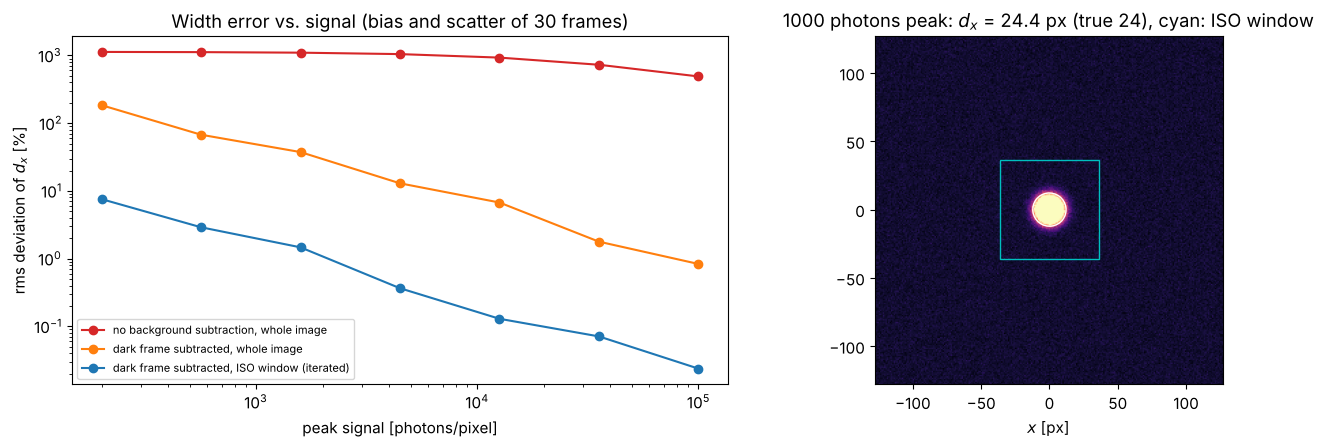

In [6]:
x, y, X, Y = grid2d(-128, 128, -128, 128, 256)   # pixel units
w_px = 12.0
beam = np.exp(-2*(X**2 + Y**2)/w_px**2)
camera = CameraNoiser(model="camera", read_noise=5.0, gain=1.0, offset=100.0, rng=1)
dark = np.mean([camera(np.zeros_like(beam)) for _ in range(20)], axis=0)

peaks = np.logspace(np.log10(200), 5, 7)
methods = {
    "no background subtraction, whole image": dict(background=0.0, iterate=False),
    "dark frame subtracted, whole image": dict(background=dark, iterate=False),
    "dark frame subtracted, ISO window (iterated)": dict(background=dark, iterate=True),
}
def width_or_nan(F, **kwargs):
    with warnings.catch_warnings(), np.errstate(invalid="ignore"):
        warnings.simplefilter("ignore")  # non-converged iterations at the lowest signals
        try:
            return beam_widths(F, x, y, **kwargs).d_x
        except ValueError:  # iteration failed: signal too low
            return np.nan

errors = {m: [] for m in methods}
for peak in peaks:
    frames = [camera(Scaler(peak)(beam)) for _ in range(30)]
    for m, kwargs in methods.items():
        d = np.array([width_or_nan(F, **kwargs) for F in frames])
        # nan: negative variances, the moments of the whole noisy image are undefined
        errors[m].append((np.nanmean(d)/(2*w_px) - 1, np.nanstd(d)/(2*w_px), np.mean(np.isnan(d))))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for (m, err), color in zip(errors.items(), ("C3", "C1", "C0")):
    err = np.array(err)
    axes[0].loglog(peaks, 100*np.hypot(err[:, 0], err[:, 1]), "o-", color=color, label=m)
axes[0].set_xlabel("peak signal [photons/pixel]"); axes[0].set_ylabel("rms deviation of $d_x$ [%]")
axes[0].set_title("Width error vs. signal (bias and scatter of 30 frames)"); axes[0].legend(fontsize=8)

F = camera(Scaler(1000.0)(beam))
b = beam_widths(F, x, y, background=dark)
axes[1].imshow(F - dark, extent=(x[0], x[-1], y[0], y[-1]), cmap="magma", vmin=-20, vmax=200)
half = 1.5*b.d_r   # round beam (ellipticity > 0.87): square window aligned with x and y
axes[1].add_patch(plt.Rectangle((b.x_c - half, b.y_c - half), 2*half, 2*half, fill=False, color="c"))
axes[1].add_patch(Ellipse((b.x_c, b.y_c), b.d_x, b.d_y, angle=np.rad2deg(b.phi), fill=False, color="w", lw=1))
axes[1].set_title(f"1000 photons peak: $d_x$ = {b.d_x:.1f} px (true 24), cyan: ISO window")
axes[1].set_xlabel("$x$ [px]")
fig.tight_layout()

Without background subtraction the offset of 100 DN over the whole sensor
makes the "width" meaningless (errors of several 100 %). Subtracting a dark
frame removes the offset, but the noise of 65 000 pixels, weighted with
their squared distance from the beam, still biases and scatters the result;
at low signal the variances of the whole image can even become negative
(those frames are left out above). The iterated 3 × window keeps only the
region that carries the beam: its error falls from 7 % at 200 photons per
pixel to 1.4 % at 1600 and below 0.5 % from 5000 on. The whole image needs 20
to 100 times more signal for the same accuracy. (The window truncates the
Gaussian at $\pm 3w$, which changes its second moments by less than $10^{-6}$.)

`beam_widths()` starts the iteration from the region above half the
maximum and lets the window grow from there. Below about 100 photons per
pixel the maximum of the image can be a noise spike, the iteration wanders
or fails (`beam_widths()` then raises an error or warns), as it would in the
lab: average frames first.